# `Сегментация изображений`

#### Фамилия, имя:

Дата выдачи: <span style="color:red">__16 октября__</span>.

Мягкий дедлайн: <span style="color:red">__30 октября 23:59__</span>.

Жесткий дедлайн: <span style="color:red">__6 ноября 23:59__</span>.

Стоимость: __10 баллов__ (основная часть заданий) + __4.25 балла__ (дополнительные задания).

<span style="color:yellow">__*Штраф за позднюю сдачу дз:* за каждый день просрочки после мягкого дедлайна начисляется штраф в размере 10% до наступления жесткого дедлайна. Работы, поданные после жесткого дедлайна, не принимаются.__</span>

<span style="color:red">__В ноутбуке все клетки должны выполняться без ошибок при последовательном их выполнении.__</span>

В этом задании вы будете решать задачу сегментации людей на фотографии с помощью нейросетевых архитектур `U-Net` и `LinkNet`.

Данные для выполнения задания можно скачать по [ссылке](https://disk.yandex.ru/d/tI6d3LBMHTwOnw).

Везде, где требуется использование `wandb`, вы можете использовать незаблокированные аналоги.

## `Загрузка данных (1 балл)`

Для загрузки данных pytorch опирается на такую сущность, как **`Dataset`**.

Этот абстрактный класс определен в `torch.utils.data.dataset`:

```python
class Dataset(object):
    """An abstract class representing a Dataset.

    All other datasets should subclass it. All subclasses should override
    ``__len__``, that provides the size of the dataset, and ``__getitem__``,
    supporting integer indexing in range from 0 to len(self) exclusive.
    """

    def __getitem__(self, index):
        raise NotImplementedError

    def __len__(self):
        raise NotImplementedError

    def __add__(self, other):
        return ConcatDataset([self, other])
```
При определении нового источника данных мы создаем наследника данного класса и реализуем методы `__getitem__` и `__len__`.

Пример готового такого класса — `torchvision.datasets.ImageFolder`, который позволяет создать датасет на основе директории с ImageNet-подобной структурой поддиректорий (`./train/{class}` и `./val/{class}`):

```python
imagenet = torchvision.datasets.ImageFolder('path/to/imagenet_root/')
```

Реализуйте класс `PhotosDataset` для выданных данных.

**Внимание.** Возможно, стоит прочитать следующий пункт задания, чтобы реализация была удобной.

In [1]:
import os

import numpy as np
import numpy.testing as npt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.models import vgg13, VGG13_Weights

import matplotlib_inline
import matplotlib.pyplot as plt

%matplotlib inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

In [2]:
from google.colab import drive
import os
import zipfile

drive.mount("/content/drive")

DATA_PATH = "/content/people_data"

if not os.path.isdir(DATA_PATH):
    with zipfile.ZipFile("/content/drive/MyDrive/people_data.zip") as archive:
        archive.extractall("/content")

print(os.listdir(DATA_PATH))

Mounted at /content/drive
['test_mask', 'train_mask', 'train', 'test']


In [3]:
class PhotosDataset(Dataset):
    def __init__(self, images_dir, target_dir=None, transforms=None):
        """
        Arguments
        ---------
        images_dir : str
            Path to directory with images

        target_dir : str
            Path to directory with masks.
            Each mask corresponds to one image.
            Corresponding mask and image have the same name, but different format.

        transforms : some collection
            Sequence of transformations for images and masks.
        """
        self.images_dir, self.target_dir, self.transforms = images_dir, target_dir, transforms
        self.files = sorted(f for f in os.listdir(images_dir) if f.lower().endswith((".jpg", ".jpeg", ".png")))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        """
        Arguments
        ---------
        idx : int
            Index of image and mask

        Returns
        -------
        (image, mask)
        """
        from PIL import Image

        name = self.files[idx]
        image = Image.open(os.path.join(self.images_dir, name)).convert("RGB")
        if self.target_dir is not None:
            mask = Image.open(os.path.join(self.target_dir, os.path.splitext(name)[0] + ".png")).convert("L")
        else:
            mask = None
        if self.transforms is not None:
            for transform in self.transforms:
                image, mask = transform(image, mask)
        return image, mask

## `Модуль аугментации (2 балла)`

Конструктор стандартного `ImageFolder`, принимает параметр `transform` (и иногда `target_transform`).

Они служат для того, чтобы загружаемые изображения (обычно это `PIL.Image`) или таргеты преобразовывать в тензоры нужного вида.

В `torchvision` входит модуль `transforms` для стандартных примеров таких преобразований. В `transforms` могут содержаться случайные преобразования, это самый простой путь для реализации аугментации данных.

При определении кастомного трансформера помимо конструктора нужно реализовать лишь метод `__call__`:

```python
class HorizontalFlip(object):
    def __init__(self, mode=0):
        self.method = mode

    def __call__(self, img):
        """
        Args:
            img (PIL.Image): Image to be flipped.

        Returns:
            PIL.Image: Randomly flipped image.
        """
        if self.method:
            return img.transpose(Image.FLIP_LEFT_RIGHT)
        return img

```

С полным списком стандартных преобразований можно ознакомиться в [документации](https://pytorch.org/vision/0.12/transforms.html).

В данной части вам предлагается самостоятельно реализовать несколько кастомных трансформеров.
Обратите внимание, что для некоторых трансформеров, необходимо преобразовывать и изображение, и маску, а для каких-то только изображение.

Один из путей реализации:
* реализовать декоратор, делающий любое преобразование случайным
* реализовать декоратор, применяющий преобразование и к изображению, и к маске

Список трансформеров, которые надо реализовать:

1. случайное (с вероятностью $p$) горизонтальное отображение (flip) изображения
2. случайное (с вероятностью $p$) вырезание фрагмента изображения (заданного или случайного размера)
3. случайное (с вероятностью $p$) изменение яркости изображения (на заданную или случайную величину)
4. случайное (с вероятностью $p$) изменение фона изображения (на изображение из заданного списка изображений)

Используйте разумные пределы для аугментаций. Одной из причин плохого обучения модели могут быть слишком сильные аугментации. Визуально убедитесь, что граничные случаи достаточно адекватны задаче.

Обратите внимание, что под вырезанием фрагмента подрузумевается вырезания части изображения из исходного, то есть вырезание какой-то части изображения (создание отверстий в изображении). Если после слоя вырезания размеры изображения поменялись, то вы неправильно реализовали модуль.

я не стала делать декоратор на применение к изображению и маске, так как там были бы сложности в сutout из-за случайности окна.

In [4]:
import random
from PIL import Image, ImageEnhance
from torchvision.transforms import functional as TF


def random_apply(transform):
    def wrapper(self, image, mask):
        if random.random() < self.p:
            return transform(self, image, mask)
        return image, mask
    return wrapper


class HorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    @random_apply
    def __call__(self, image, mask):
        image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT) if mask is not None else None
        return image, mask


class Cutout:
    def __init__(self, p=0.3, size=(0.05, 0.2)):
        self.p, self.size = p, size

    @random_apply
    def __call__(self, image, mask):
        w, h = image.size
        cw, ch = int(w * random.uniform(*self.size)), int(h * random.uniform(*self.size))
        x, y = random.randint(0, w - cw), random.randint(0, h - ch)
        image = np.array(image)
        image[y:y + ch, x:x + cw] = 0
        if mask is not None:
            mask = np.array(mask)
            mask[y:y + ch, x:x + cw] = 0
            mask = Image.fromarray(mask)
        image = Image.fromarray(image)
        return image, mask


class BrightnessAdjust:
    def __init__(self, p=0.2, brightness=(0.7, 1.3)):
        self.p, self.brightness = p, brightness

    @random_apply
    def __call__(self, image, mask):
        image = ImageEnhance.Brightness(image).enhance(random.uniform(*self.brightness))
        return image, mask


class BackgroundReplace:
    def __init__(self, backgrounds, p=0.3):
        self.backgrounds, self.p = backgrounds, p

    @random_apply
    def __call__(self, image, mask):
        if mask is None:
            return image, mask
        background = random.choice(self.backgrounds).resize(image.size)
        image, background = np.array(image), np.array(background)
        foreground = np.array(mask) > 0
        image[~foreground] = background[~foreground]
        return Image.fromarray(image), mask


class ToTensorNormalize:
    def __call__(self, image, mask):
        image = TF.normalize(TF.to_tensor(image), [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        return image, torch.from_numpy(np.array(mask)).long() if mask is not None else None

def extract_backgrounds(images_dir, masks_dir, max_bg=50):
    backgrounds = []
    for name in os.listdir(images_dir):
        path = os.path.join(masks_dir, os.path.splitext(name)[0] + ".png")
        if not os.path.exists(path):
            continue
        image = np.array(Image.open(os.path.join(images_dir, name)).convert("RGB"))
        mask = np.array(Image.open(path).convert("L"))
        image[mask > 0] = 0
        backgrounds.append(Image.fromarray(image))
        if len(backgrounds) >= max_bg:
            break
    return backgrounds


Добавьте случайные преобразования в ваши датасеты. Также, добавьте преобразование в tensor и нормализацию для изображения:

```python
transforms.ToTensor()
transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)
```

In [5]:
DATA_PATH = "people_data"

bg_images = extract_backgrounds(os.path.join(DATA_PATH, "train"), os.path.join(DATA_PATH, "train_mask"))

train_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'train'),
    target_dir=os.path.join(DATA_PATH, 'train_mask'),
    transforms=[
        HorizontalFlip(), Cutout(), BrightnessAdjust(),
        BackgroundReplace(bg_images), ToTensorNormalize()
    ]
)

test_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'test'),
    target_dir=os.path.join(DATA_PATH, 'test_mask'),
    transforms=[ToTensorNormalize()]
)

Функция для отображения изображения:

In [6]:
def show_idx_image(dataset, idx):
    image, mask = dataset[idx]

    image = image.permute(1, 2, 0).numpy()
    image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    mask = mask.squeeze(0).numpy()

    fig, axes = plt.subplots(1, 2, figsize=(6, 4))

    axes[0].imshow(image)
    axes[1].imshow(mask)

    axes[0].set_axis_off()
    axes[1].set_axis_off()

    fig.tight_layout()
    plt.show()

Отобразите несколько изображений и масок, на которых будет видна правильная работа вашего модуля аугментации данных. Необходимо проверить каждый модуль аугментации отдельно, в ином случае будут сниматься баллы.

**Важно:** Проверьте корректность работы модулей, действительно ли маска изображения корректна для изображения после аугментации.

Original


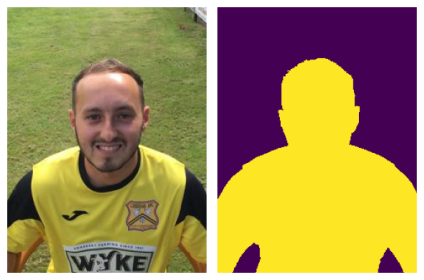

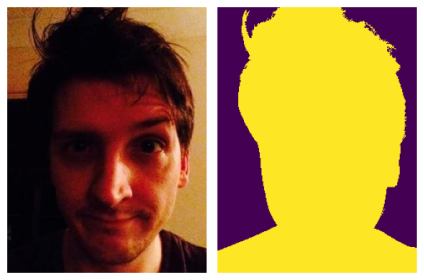

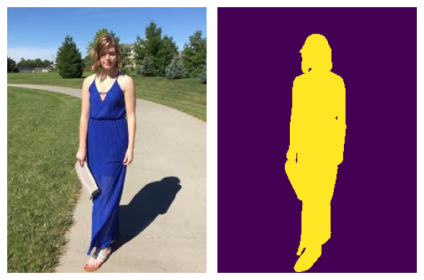

HorizontalFlip


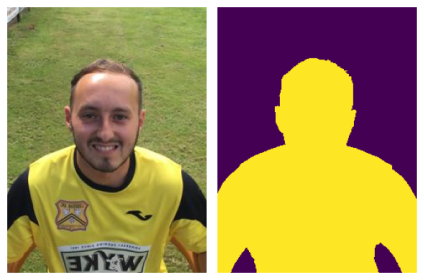

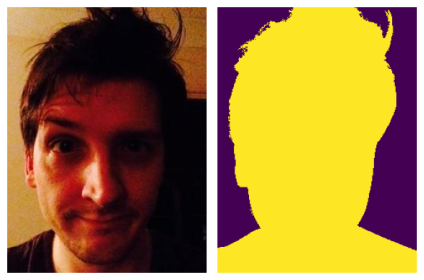

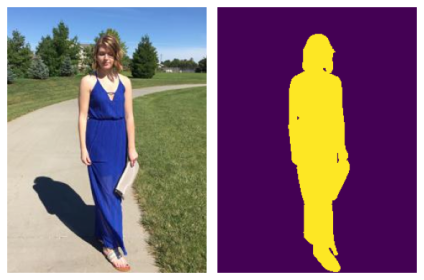

Cutout


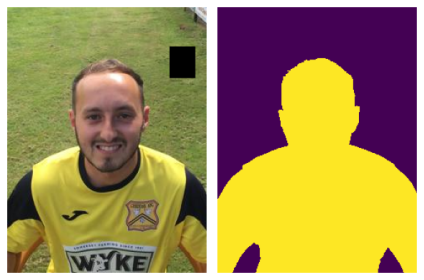

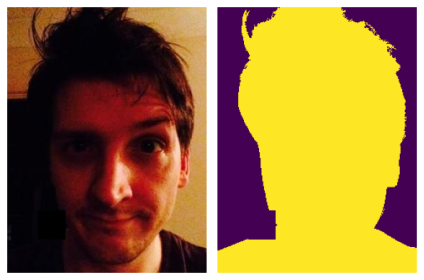

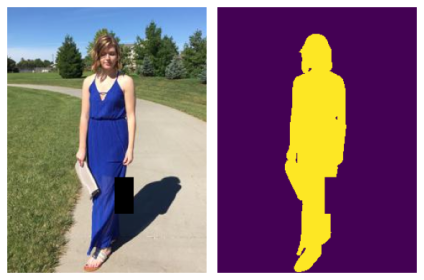

BrightnessAdjust


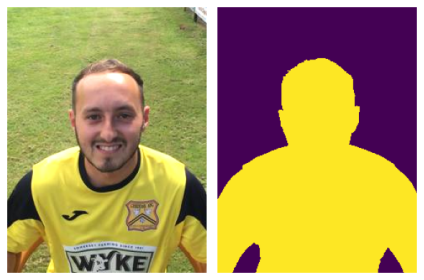

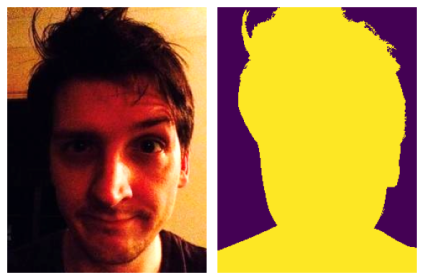

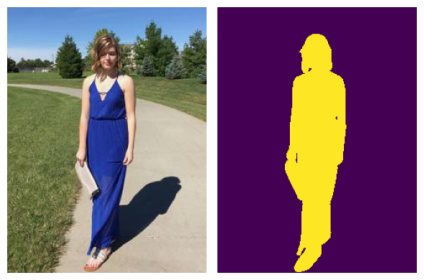

BackgroundReplace


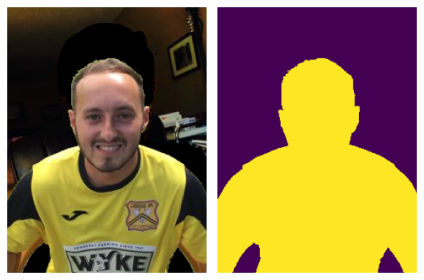

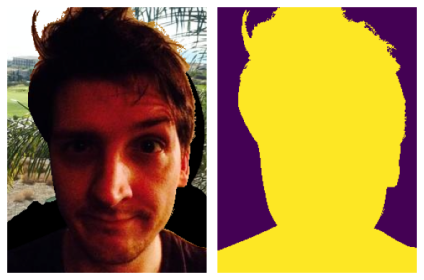

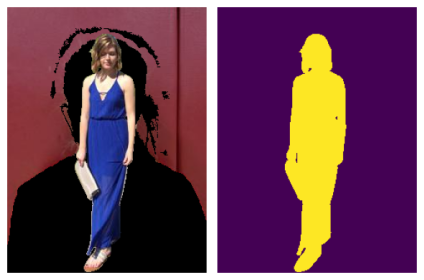

In [7]:
indices = random.sample(range(len(train_dataset)), 3)
for transform in [None, HorizontalFlip(p=1), Cutout(p=1),
                  BrightnessAdjust(p=1), BackgroundReplace(bg_images, p=1)]:
    print(type(transform).__name__ if transform is not None else "Original")
    dataset = PhotosDataset(
        images_dir=os.path.join(DATA_PATH, "train"),
        target_dir=os.path.join(DATA_PATH, "train_mask"),
        transforms=([transform] if transform is not None else []) + [ToTensorNormalize()]
    )
    for idx in indices:
        show_idx_image(dataset, idx)


## `Загрузчики`

При обучении сети удобнее работать не с датасетами, а с загрузчиками. Загрузчики создаются на основе датасета и позволяют итерироваться по батчам из него.

Обратите внимание на параметры `DataLoader`. При `num_workers`$\;> 1$, батчи готовятся (загружаются картинки, обрабатываются и так далее) сразу в нескольких фоновых процессах. С помощью параметра `shuffle` можно подавать картинки на обучение в случайном порядке.

Обычно, скорость обработки данных на GPU превышает скорость загрузки данных в одном процессе, поэтому типичное значение для `num_workers`$\approx 3\text{-}10$.

Учтите, что на некоторых системах в Jupyter Notebook при `num_workers`$>0$ `DataLoader` перестаёт работать. В таком случае установите это значение в $0$.

In [8]:
test_data_loader = DataLoader(test_dataset, batch_size=8, num_workers=0)
train_data_loader = DataLoader(train_dataset, batch_size=8, num_workers=0, shuffle=True)

## `DiceLoss (1 балл)`

Функция потерь реализовывается как и все стандартные нейронные модули в pytorch, через `torch.nn.Module`. В ячейке ниже вам предлагается реализовать функцию потерь `dice` (аналог меры Жаккарда).

Результат **Dice Loss** определим как:

$$
\text{Dice Coefficient} = 2\frac{|A \cap B| }{|A| + |B|} \leadsto \text{Dice Loss} = 1 - \frac{2\sum\limits_{i, j}a_{ij}b_{ij}}{\sum\limits_{ij}(a_{ij} + b_{ij} + \varepsilon)}
$$

где $a_{ij} \in [0, 1]$ — предсказанная вероятность нахождения человека в пикселе изображения, $b_{ij}$ — истинная разметка для пикселя изображения.

In [9]:
class DiceLoss(torch.nn.Module):
    def __init__(self, eps=1e-7, reduction=None, with_logits=True):
        """
        Arguments
        ---------
        eps : float
            eps in denominator
        reduction : Optional[str] (None, 'mean' or 'sum')
            specifies the reduction to apply to the output:

            None: no reduction will be applied
            'mean': the sum of the output will be divided by the number of elements in the batch
            'sum':  the output will be summed.
        with_logits : bool
            If True, use additional sigmoid for inputs
        """
        super().__init__()
        self.eps = eps
        self.reduction = reduction
        self.with_logits = with_logits

    def forward(self, logits, true_labels):
        """
        Arguments
        ---------
        logits: torch.Tensor
            Unnormalized probability of true class. Shape: [B, ...]
        true_labels: torch.Tensor
            Mask of correct predictions. Shape: [B, ...]
        Returns
        -------
        torch.Tensor
            If reduction is 'mean' or 'sum' returns a tensor with a single element
            Otherwise, returns a tensor of shape [B]
        """
        true_labels = true_labels.to(torch.long)

        if self.with_logits:
            logits = torch.sigmoid(logits)

        logits, true_labels = logits.flatten(1), true_labels.flatten(1)
        loss = 1 - 2 * (logits * true_labels).sum(1) / (logits + true_labels + self.eps).sum(1)

        if self.reduction == 'sum':
            loss_value = loss.sum()
        elif self.reduction == 'mean':
            loss_value = loss.mean()
        elif self.reduction is None:
            loss_value = loss

        return loss_value

Проверка реализации:

In [10]:
logits = torch.tensor([
    [[0, 0.5], [0.5, 1]],
    [[0.1, 0.1], [0, 0]],
])

target = torch.tensor([
    [[0, 1], [1, 1]],
    [[1, 0], [0, 1]],
])

losses = DiceLoss(with_logits=False, reduction=None, eps=1e-7)(logits, target)
npt.assert_almost_equal(losses.numpy(), np.array([0.2, 0.90909]), decimal=4)

loss = DiceLoss(with_logits=False, reduction='mean', eps=1e-7)(logits, target)
npt.assert_almost_equal(float(loss.numpy()), 0.554545, decimal=4)

loss = DiceLoss(with_logits=False, reduction='sum', eps=1e-7)(logits, target)
npt.assert_almost_equal(float(loss.numpy()), 1.10909, decimal=4)

## `U-Net (3 балла)`

Для решения задачи сегментации будем использовать [U-Net](https://arxiv.org/pdf/1505.04597.pdf) с энкодером из первых блоков предобученного `VGG13`.

Концептуальная схема представлена на диаграмме ниже:

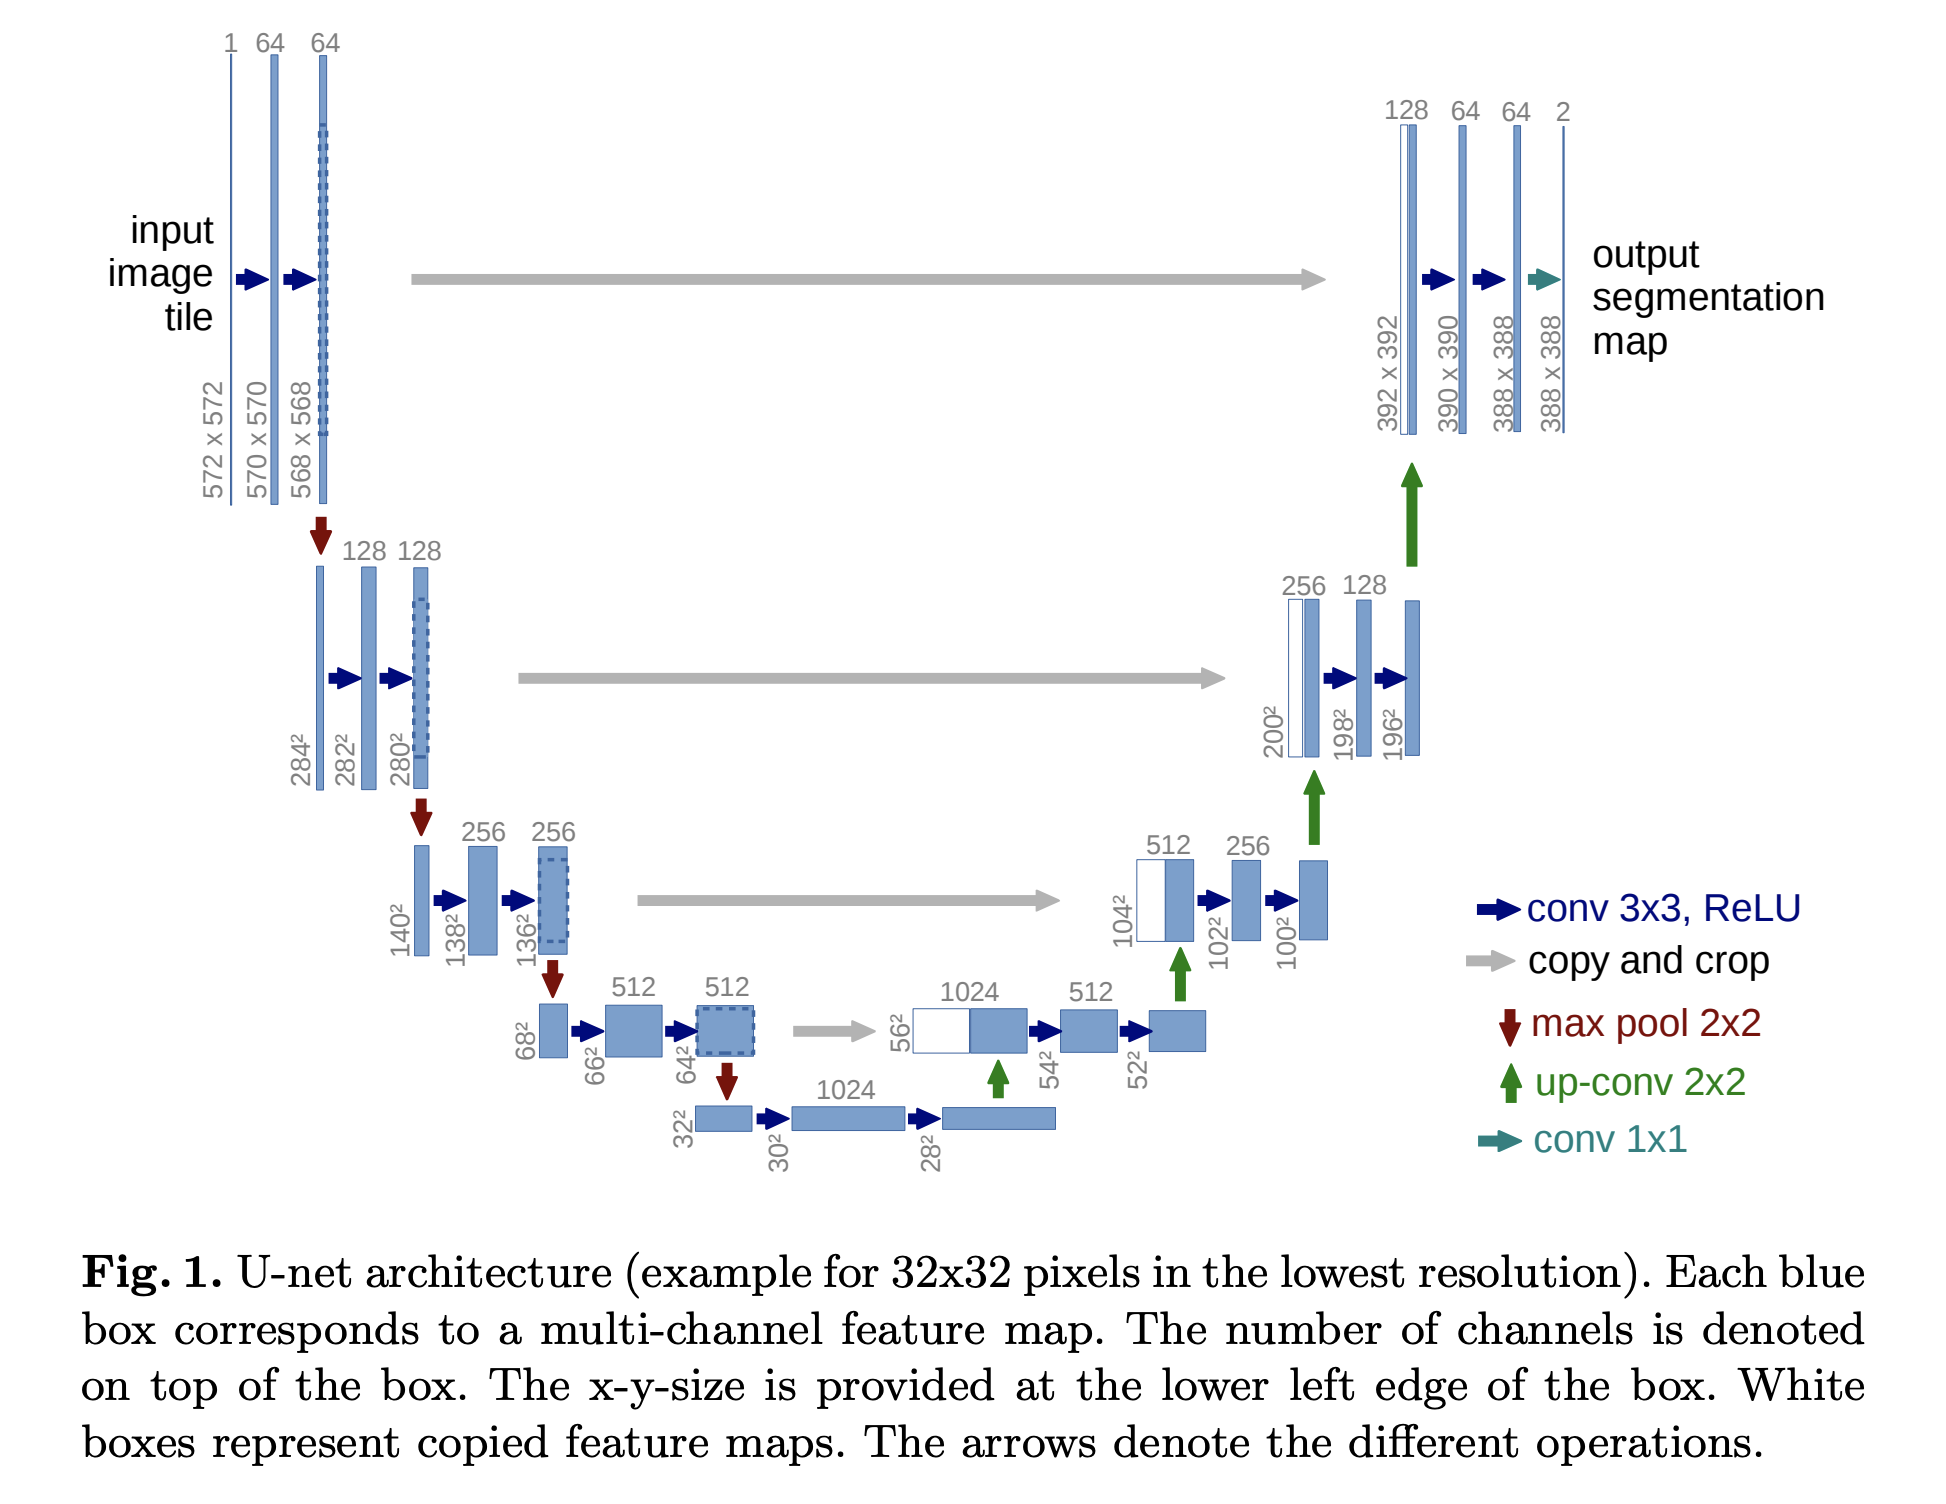

Заметим, что блоки VGG13 имеют следующий вид:
```python
    (0): Conv2d(...)
    (1): ReLU(...)
    (2): Conv2d(...)
    (3): ReLU(...)
    (4): MaxPool2d(...)
```

Для удобства, уберём слои `MaxPool2d` из блоков энкодера и будем применять pooling отдельно. Возможно, вам будет полезно вывести архитектуру модели `VGG` и изучить параметры слоев pooling.

При реализации `Decoder` вам пригодится интерполяция, для этого можно использовать `torch.nn.functional.interpolate` с `mode=nearest`.

Реализуйте архитектуру данной сети.

#### `Encoder`

In [11]:
class VGG13Encoder(torch.nn.Module):
    def __init__(self, num_blocks, weights=VGG13_Weights.DEFAULT):
        super().__init__()
        self.num_blocks = num_blocks

        # Будем использовать предобученную VGG13 в качестве backbone
        feature_extractor = vgg13(weights=weights).features

        # Каждый блок энкодера U-Net — это блок VGG13 без MaxPool2d
        self.blocks = torch.nn.ModuleList()
        for idx in range(self.num_blocks):
            # Возьмите нужные слои из `feature_extractor` для очередного U-Net блока
            # Объедините их с помощью `torch.nn.Sequential`
            self.blocks.append(
                torch.nn.Sequential(*feature_extractor[5 * idx:5 * idx + 4])
            )

    def forward(self, x):
        activations = []
        for idx, block in enumerate(self.blocks):
            # Примените очередной блок U-Net
            x = block(x)

            # Сохраните активации для передачи их в декодер
            activations.append(x)

            # При необходимости примените max-pool
            # Можно использовать `torch.functional.F.max_pool2d`
            if idx < self.num_blocks - 1:
                x = torch.nn.functional.max_pool2d(x, 2)

        return activations

In [12]:
assert sum((param.numel() for param in VGG13Encoder(num_blocks=1).parameters())) == 38720
assert sum((param.numel() for param in VGG13Encoder(num_blocks=2).parameters())) == 260160
assert sum((param.numel() for param in VGG13Encoder(num_blocks=3).parameters())) == 1145408

x = torch.arange(1 * 3 * 320 * 240).reshape(1, 3, 320, 240) / (1 * 3 * 320 * 240)
out = VGG13Encoder(num_blocks=3)(x)

assert len(out) == 3
npt.assert_almost_equal(torch.linalg.norm(out[0]).item(), 902.218, decimal=3)
npt.assert_almost_equal(torch.linalg.norm(out[1]).item(), 571.030, decimal=3)
npt.assert_almost_equal(torch.linalg.norm(out[2]).item(), 648.068, decimal=3)

Downloading: "https://download.pytorch.org/models/vgg13-19584684.pth" to /root/.cache/torch/hub/checkpoints/vgg13-19584684.pth


100%|██████████| 508M/508M [00:04<00:00, 130MB/s]


#### `Decoder`

In [13]:
class DecoderBlock(torch.nn.Module):
    def __init__(self, out_channels):
        super().__init__()

        self.upconv = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv1 = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv2 = torch.nn.Conv2d(
            in_channels=out_channels, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.relu = torch.nn.ReLU()

    def forward(self, down, left):
        # Upsample x2 и свёртка
        x = self.upconv(torch.nn.functional.interpolate(down, scale_factor=2, mode="nearest"))

        # Конкатенация выхода энкодера и предыдущего блока декодера
        x = torch.cat([x, left], dim=1)

        # Две свёртки с ReLu
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        return x

In [14]:
class Decoder(torch.nn.Module):
    def __init__(self, num_filters, num_blocks):
        super().__init__()

        self.blocks = torch.nn.ModuleList()
        for idx in range(num_blocks):
            self.blocks.insert(0, DecoderBlock(num_filters * 2 ** idx))

    def forward(self, acts):
        up = acts[-1]
        for block, left in zip(self.blocks, acts[-2::-1]):
            up = block(up, left)
        return up

#### `U-Net`

In [15]:
class UNet(torch.nn.Module):
    def __init__(self, num_classes=1, num_blocks=4):
        super().__init__()
        self.encoder = VGG13Encoder(num_blocks)

        self.decoder = Decoder(64, num_blocks - 1)

        # Свёртка 1x1 для попиксельной агрегации каналов
        self.final = torch.nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        x = self.final(self.decoder(self.encoder(x)))

        return x

In [16]:
model = UNet(num_classes=1, num_blocks=3)
x = torch.arange(1 * 3 * 320 * 240).reshape(1, 3, 320, 240) / (1 * 3 * 320 * 240)

assert sum((param.numel() for param in model.parameters())) == 2067649
assert list(model(x).shape) == [1, 1, 320, 240]
model

UNet(
  (encoder): VGG13Encoder(
    (blocks): ModuleList(
      (0): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
      (2): Sequential(
        (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
  )
  (decoder): Decoder(
    (blocks): ModuleList(
      (0): DecoderBlock(
        (upconv): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
       

### `Оценивание качества сети`


Обычно, оптимизируемый функционал сложно интерпретировать, а так же в разных экспериментах могут использоваться разные функции потерь. Поэтому необходимо замерять и отслеживать независимую метрику качества. Предлагается использовать **IoU (Intersection over Union)** — один из стандартных вариантов для задачи сегментации:
$$
\text{IoU} = \frac{|A \cap B|}{|A \cup B|} = \frac{\sum\limits_{ij}a_{ij}b_{ij}}{\sum\limits_{ij}a_{ij} + b_{ij} - a_{ij}b_{ij}}
$$

Учтите, что знаменатель может быть равен нулю, например, если маска нулевая. Такие объекты можно не учитывать при агрегации и пропускать, так как в ином случае подсчет метрики на всем батче будет NaN. В pytorch есть встроенные для этого функции с префиксом nan.


In [17]:
class IoUScore(torch.nn.Module):
    def __init__(self, threshold, reduction=None):
        """
        Arguments
        ---------
        threshold : float
            threshold for logits binarization
        reduction : Optional[str] (None, 'mean' or 'sum')
            specifies the reduction to apply to the output:

            None: no reduction will be applied
            'mean': the sum of the output will be divided by the number of elements in the batch
            'sum':  the output will be summed.
        with_logits : bool
            If True, use additional sigmoid for inputs
        """
        super().__init__()

        self.threshold = threshold
        self.reduction = reduction

    @torch.no_grad()
    def forward(self, logits, true_labels):
        """
        Arguments
        ---------
        logits: torch.Tensor
            Unnormalized probability of true class. Shape: [B, ...]
        true_labels: torch.Tensor
            Mask of correct predictions. Shape: [B, ...]
        Returns
        -------
        torch.Tensor
            If reduction is 'mean' or 'sum' returns a tensor with a single element
            Otherwise, returns a tensor of shape [B]
        """
        preds = (logits > self.threshold).flatten(1).float()
        true_labels = true_labels.flatten(1).float()
        intersection = (preds * true_labels).sum(1)
        score = intersection / (preds + true_labels - preds * true_labels).sum(1)

        if self.reduction == 'sum':
            score = torch.nansum(score)
        elif self.reduction == 'mean':
            score = torch.nanmean(score)

        return score

In [18]:
logits = torch.tensor([
    [
        [0.3089,  0.4311, -0.9711],
        [0.9030,  1.0325, -0.7607],
        [0.9648, -0.5528, -1.1010]
    ], [
        [0.8906,  0.8099,  0.4458],
        [2.6215, -1.3198,  0.3142],
        [0.2262, -0.9175, -0.0174]
    ], [
        [0.8906,  0.8099,  0.4458],
        [2.6215, -1.3198,  0.3142],
        [0.2262, -0.9175, -0.0174]
    ]
])
true_labels = torch.tensor([
    [
        [0., 1., 0.],
        [1., 0., 0.],
        [0., 0., 1.]
    ], [
        [1., 1., 1.],
        [1., 0., 1.],
        [1., 0., 0.]
    ], [
        [1., 1., 1.],
        [0., 1., 1.],
        [1., 1., 1.]
    ]
])

scores = IoUScore(0.0)(logits, true_labels)
npt.assert_almost_equal(scores.numpy(), np.array([0.3333, 1.0000, 0.5556]), decimal=4)

score = IoUScore(0.0, reduction='sum')(logits, true_labels)
npt.assert_almost_equal(score.item(), 1.8889, decimal=4)

score = IoUScore(0.0, reduction='mean')(logits, true_labels)
npt.assert_almost_equal(score.item(), 0.6296, decimal=4)

### `Логирование`

При реализации цикла обучения необходимо сохранять метрики $1\text{-}9$ с использованием модуля [torch.utils.tensorboard](https://pytorch.org/docs/stable/tensorboard.html) или с помощью модуля [wandb](https://docs.wandb.ai/tutorials/) вам предлагается самим выбрать более удобный для вас модуль.

Для отслеживания процесса обучения обычно требуется сохранять информацию разных его аспектах.

Для полного контроля над процессом обучения обычно требуется сохранять информацию о разных статистиках. Самыми очевидными являются:
1. Значение функции потерь (лосса) на обучающей и тестовой выборках
2. Метики качества, например, **Dice Coefficient** и **IoU (Intersection over Union)** на обучающей и тестовой выборках

Однако, суррогатные метрики могут не отражать реального качества. Поэтому для моделей, которые выдают визуализируемый результат, обычно логируют предсказания для некоторых объектов выборки. В задаче сегментации естественным вариантом является логирование четвёрки: исходное изображение, истинная маска, маска вероятностей истинного класса, бинаризованная маска.

*Замечание:* лосс и качество на обучающей выборке обычно логируют не только в конце каждой эпохи, но и по отдельным батчам на каждой итерации.

3. Чтобы отслеживать динамику обучения необходимо зафиксировать небольшой набор объектов обучающей и тестовой выборок и после каждой эпохи обучения логировать указанные четыре картинки для каждого объекта.

*Замечание:* можно логировать четвёрки изображений независимо, однако, удобнее объединить их на одной фигуре [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_figure), [реализация через Wandb](https://docs.wandb.ai/guides/track/log/plots/#matplotlib-and-plotly-plots) (лучше делать через fig и Image). Дополнительный плюс — возможность подписать значения метрик для этого объекта в заголовке изображения или добавить colorbar для более простой интерпретации предсказанной маски.

Для удобной категоризации экспериментов обычно в начале обучения сохраняют:

4. Гиперпараметры модели [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_hparams), [реализация через Wandb](https://docs.wandb.ai/guides/track/config/)
5. Структуру модели [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_graph), **про реализацию wandb ниже**

Для исследования технических особенностей обучения полезно логировать следующие статистики:

6. Распределение весов, активаций, градиентов [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_histogram), [реализация через Wandb](https://docs.wandb.ai/ref/python/data-types/histogram/). Сохранять гистограммы каждого параметра после каждой итерации может быть вычислительно неэффективно, поэтому обычно сохраняют распределения весов для каждого отдельного слоя нейронной сети после каждой эпохи.
7. Норма весов и норма градиента на каждой итерации

Наконец, после каждой эпохи можно визуализировать промежуточные представления входных данных:

8. Активации после каждого слоя/блока, как изображения
9. Градиенты функции потерь по активациям для некоторых объектов обучающей выборки, как изображения

*Замечание:* для реализации пунктов 8, 9 менять код модели не требуется. Используйте хуки: [register_full_backward_hook](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook) (данный хук не работает с inplace операциями, например, с `torch.nn.ReLU(inplace=True)`. Или не используйте inplace операции, или используйте [`Tensor.register_hook`](https://github.com/pytorch/pytorch/issues/61519)), [register_forward_hook](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook).

Файлы с логами, а также чекпоинты весов модели после итерации с наилучшим валидационным качеством (смотрите [torch.save](https://pytorch.org/docs/stable/generated/torch.save.html) и [torch.nn.Module.state_dict](https://pytorch.org/tutorials/recipes/recipes/what_is_state_dict.html)) для **ВСЕХ** проведённых экспериментов (за исключением упавших, недосчитанных и так далее) необходимо сдать в anytask.

#### `Некоторые советы по wandb`

- При логировании всегда указывайте параметр step, который должен не уменьшаться.

- При логировании изображений лучше их нормировать в диапазон [0, 1] как в функции `show_idx_image` выше. Для логирования предсказаний маски, лучше использовать вероятности. При неправильном диапозоне изображения могут отображаться неверно!

- Вместо логирования изображений, лучше логировать `matplotlib` графики и соответсвующие им `figure`. Кроме того, лучше закрывать все открытые графики, чтобы не перегружать ноутбук. Пример кода:


```python
fig, ax = plt.subplots(...)
...
wandb.log({key: wandb.Image(fig)}, step=global_step)
plt.close('all')
```

- Функционал построение bins в `wandb.Histogram` ограничен, можете посмотреть в сторону аргумента `np_histogram`.

- Wandb не имеет широкого функционала для логирования структуры модели. Есть способ через wandb.watch(net, log_graph=True), но получаемый результаты сильно отличаются от возможностей `tensorboard`. К счастью, `wandb` умеет синхронизировать логи с `Tensorboard` поэтому можно использовать следующую логику:


```python
wandb.init(
    project=project_name,
    name=run_name,
    config=config,
    sync_tensorboard=True        # Синхронизация с tensorboard
)

writer = SummaryWriter(run_name) # Создание логера tensorboard

# Логирование графа модели
writer.add_graph(net, input_x)
writer.close()

train_loop(...)
wandb.finish()
```

- `wandb` по умолчанию сохраняет все логи локально и на сайте в вашем личном хранилище. В случае перезагрузки `Google Colab` локальные файлы не сохраняются! Кроме того, скачивание файлов не через GoogleDisk достаточно продолжительное (в районе 20-30 минут).

- В `wandb` можно легко сохранять код и указать директорию, так вы никогда не забудете какой именно код получает результаты логов.

```python
wandb.init(..., settings=wandb.Settings(code_dir="."))
```

Кроме того, можно сохранить отдельные файлы:

```python
wandb.init(..., save_code=True)
wandb.run.log_code(
    "./",
    include_fn=lambda path: condition(path)
)
```

- В `wandb` есть функция для автоматического логирования весов и градиентов модели `wandb.watch()`, но функционал слишком ограничен и накладывает слишком много накладных расходов. **Лучше писать руками!**

#### `Некоторые советы по tensorboard`

- Функционал и возможности `tensorboard` шире (работа с 3D, продвинутые визуализации).

- `tensorboard` сохраняет логи только локально, то есть после закрытия `Google Colab` ничего не сохранится. В реальных проектах это является сильной стороной, так как гарантирует безопасность и конфиденциальность.

- Для визуализации логов достаточно запустить в ноутбуке или в терминале соответсвующее расширение, однако в случае `Google Colab` для этого приходится прокидывать порты, [подробнее тут](https://stackoverflow.com/questions/47818822/can-i-use-tensorboard-with-google-colab).

- `tensorboard` меньше лагает и более легковесный.


### `Некоторые советы по логированию`

- Вы можете выбрать либо `wandb`, либо `tensorboard`.

- В реальных проектах лучше добавить логирование кода с целью сохранения и воспроизводимости результатов.

- Называйте запуски осмысленно, чтобы по названию можно было понять смысл запуска и варьеруемые параметры.


#### Реализация логирования через wandb

Установите `wandb` и `tensorboard` в окружение ноутбука. При первом запуске wandb предложит авторизоваться. Граф модели сохраняется через TensorBoard с синхронизацией в wandb. Для каждого блока визуализируются первые восемь каналов на трёх фиксированных обучающих примерах. Перед обучением выполните следующую ячейку и разрешите Colab подключить Google Drive. Новые запуски сохраняются в `MyDrive/dl2-hw-3/wandb/run-*`: чекпоинт `best.pt`, изображения и граф модели — внутри `files`, история `.wandb` — в папке запуска. Для сдачи сохраняйте папку запуска целиком. Уже существующие локальные запуски автоматически не переносятся. При обрыве среды последние ещё не записанные или не синхронизированные данные могут потеряться.

При синхронизации TensorBoard wandb игнорирует аргумент `step`, поэтому общей осью метрик служит возрастающий `global_step`.


In [19]:
from google.colab import drive

drive.mount("/content/drive")
LOG_ROOT = "/content/drive/MyDrive/dl2-hw-3-submit"
os.makedirs(LOG_ROOT, exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import wandb
from tqdm.auto import tqdm
from torch.utils.tensorboard import SummaryWriter
from torchvision.utils import make_grid, save_image


def segmentation_metrics(logits, masks):
    preds = (logits.detach() > 0).flatten(1).float()
    masks = masks.flatten(1)
    intersection = (preds * masks).sum(1)
    total = preds.sum(1) + masks.sum(1)
    dice = ((2 * intersection + 1e-7) / (total + 1e-7)).mean()
    iou = ((intersection + 1e-7) / (total - intersection + 1e-7)).mean()
    return dice.item(), iou.item()


def prediction_images(model, samples, device, run, split, epoch, filenames):
    result = []
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    with torch.no_grad():
        for (image, mask), filename in zip(samples, filenames):
            probs = model(image[None].to(device)).sigmoid()[0, 0].cpu()
            panels = [(image * std + mean).clamp(0, 1).permute(1, 2, 0),
                      mask > 0, probs, probs > 0.5]
            fig, axes = plt.subplots(1, 4, figsize=(12, 3))
            for ax, panel, title in zip(axes, panels, ["Image", "GT", "Probability", "Binary"]):
                ax.imshow(panel, cmap="gray", vmin=0, vmax=1)
                ax.set_title(title)
                ax.axis("off")
            title = f"{run.name} | {run.id} | epoch {epoch} | {split} | {filename}"
            fig.suptitle(title)
            fig.tight_layout()
            folder = os.path.join(run.dir, "predictions", f"epoch_{epoch:03d}", split)
            os.makedirs(folder, exist_ok=True)
            fig.savefig(os.path.join(folder, os.path.splitext(filename)[0] + ".png"))
            result.append(wandb.Image(fig, caption=title))
            plt.close(fig)
    return result


def feature_images(values, run, epoch, block, kind, filenames):
    folder = os.path.join(run.dir, kind, f"epoch_{epoch:03d}", "train", block)
    os.makedirs(folder, exist_ok=True)
    result = []
    for x, filename in zip(values, filenames):
        grid = make_grid(x[:8, None], nrow=4, normalize=True, scale_each=True)
        save_image(grid, os.path.join(folder, os.path.splitext(filename)[0] + ".png"))
        title = f"{run.name} | {run.id} | epoch {epoch} | {block} | {kind} | train | {filename}"
        result.append(wandb.Image(grid, caption=title))
    return result


def log_layers(model, samples, loss_fn, device, run, epoch, filenames):
    activations, gradients, handles = {}, {}, []

    def capture(name):
        def hook(module, inputs, output):
            activations[name] = output.detach().cpu().clone()
            output.register_hook(lambda grad: gradients.update({name: grad.detach().cpu().clone()}))
        return hook

    blocks = [(f"encoder/{i}", block) for i, block in enumerate(model.encoder.blocks)]
    blocks += [(f"decoder/{i}", block) for i, block in enumerate(model.decoder.blocks)]
    blocks.append(("final", model.final))
    blocks += [(f"aux/{i}", head) for i, head in enumerate(getattr(model, "aux_heads", []))]
    images = torch.stack([image for image, mask in samples]).to(device)
    masks = torch.stack([mask > 0 for image, mask in samples])[:, None].float().to(device)
    model.zero_grad(set_to_none=True)
    try:
        for name, block in blocks:
            handles.append(block.register_forward_hook(capture(name)))
        outputs = model(images, return_aux=True) if hasattr(model, "aux_heads") else model(images)
        logits = outputs[0] if isinstance(outputs, tuple) else outputs
        loss = loss_fn(logits, masks)
        if isinstance(outputs, tuple):
            loss = loss + sum(w * loss_fn(aux, masks) for w, aux in zip([0.5, 0.25], outputs[1]))
        loss.backward()
        logs = {}
        for name, param in model.named_parameters():
            logs[f"weights/{name}"] = wandb.Histogram(param.detach().cpu().numpy())
            if param.grad is not None:
                logs[f"gradients/{name}"] = wandb.Histogram(param.grad.detach().cpu().numpy())
        for name in activations:
            logs[f"activations/{name}"] = wandb.Histogram(activations[name].numpy())
            logs[f"activation_gradients/{name}"] = wandb.Histogram(gradients[name].numpy())
            logs[f"features/{name}"] = feature_images(activations[name], run, epoch, name, "features", filenames)
            logs[f"feature_gradients/{name}"] = feature_images(gradients[name], run, epoch, name, "feature_gradients", filenames)
        return logs
    finally:
        for handle in handles:
            handle.remove()
        model.zero_grad(set_to_none=True)


In [34]:
def train_experiment(model, train_loader, test_loader, loss_fn, config, run_name):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    fixed, filenames = {}, {}
    for split, loader in [("train", train_loader), ("test", test_loader)]:
        dataset = PhotosDataset(loader.dataset.images_dir, loader.dataset.target_dir,
                                transforms=[ToTensorNormalize()])
        fixed[split] = [dataset[i] for i in [0, 1, 2]]
        filenames[split] = [dataset.files[i] for i in [0, 1, 2]]

    config = {**config, "model": type(model).__name__, "model_structure": str(model),
              "optimizer": "Adam", "loss": str(loss_fn),
              "batch_size": train_loader.batch_size, "threshold": 0.5}
    experiment_dir = os.path.join(LOG_ROOT, run_name)
    os.makedirs(experiment_dir, exist_ok=True)
    with wandb.init(project="dl2-segmentation", name=run_name, config=config,
                    sync_tensorboard=True, dir=experiment_dir) as run:
        print(f"{run_name} | {run.id} | Files: {run.dir}")
        run.define_metric("global_step")
        run.define_metric("*", step_metric="global_step")
        logdir = os.path.join(run.dir, "tensorboard")
        model.eval()
        with SummaryWriter(logdir) as writer:
            writer.add_graph(model, fixed["train"][0][0][None].to(device))
        best_iou, step = -1, 1
        for epoch in range(config["epochs"]):
            if epoch == config.get("finetune_epoch"):
                optimizer = torch.optim.Adam(model.parameters(), lr=config["finetune_lr"])
            logs = {"epoch": epoch + 1, "lr": optimizer.param_groups[0]["lr"]}
            for split, loader in [("train", train_loader), ("test", test_loader)]:
                training = split == "train"
                model.train(training)
                totals = np.zeros(3)
                count = 0
                for images, masks in tqdm(loader, desc=f"Epoch {epoch + 1}/{config['epochs']} | {split}", leave=False):
                    images = images.to(device)
                    masks = (masks > 0).float().unsqueeze(1).to(device)
                    with torch.set_grad_enabled(training):
                        outputs = model(images)
                        logits = outputs[0] if isinstance(outputs, tuple) else outputs
                        loss = loss_fn(logits, masks)
                        if isinstance(outputs, tuple):
                            loss = loss + sum(w * loss_fn(aux, masks)
                                              for w, aux in zip([0.5, 0.25], outputs[1]))
                        dice, iou = segmentation_metrics(logits, masks)
                        if training:
                            optimizer.zero_grad(set_to_none=True)
                            loss.backward()
                            weight_norm = sum(p.detach().square().sum() for p in model.parameters()).sqrt()
                            grad_norm = sum(p.grad.detach().square().sum() for p in model.parameters()
                                            if p.grad is not None).sqrt()
                            run.log({"batch/loss": loss.item(), "batch/dice": dice, "batch/iou": iou,
                                     "norm/weights": weight_norm.item(), "norm/gradients": grad_norm.item(),
                                     "global_step": step})
                            step += 1
                            optimizer.step()
                    totals += np.array([loss.item(), dice, iou]) * len(images)
                    count += len(images)
                logs.update({f"{split}/{key}": value for key, value in
                             zip(["loss", "dice", "iou"], totals / count)})
            model.eval()
            for split, samples in fixed.items():
                logs[f"predictions/{split}"] = prediction_images(model, samples, device, run, split, epoch + 1, filenames[split])
            logs.update(log_layers(model, fixed["train"], loss_fn, device, run, epoch + 1, filenames["train"]))
            run.log({**logs, "global_step": step})
            step += 1
            if logs["test/iou"] > best_iou:
                best_iou = float(logs["test/iou"])
                torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                            "epoch": epoch + 1, "step": step, "config": config,
                            "test_iou": best_iou}, os.path.join(run.dir, "best.tmp.pt"))
                os.replace(os.path.join(run.dir, "best.tmp.pt"), os.path.join(run.dir, "best.pt"))
            print(f"{run_name} | Epoch {epoch + 1}: train loss={logs['train/loss']:.4f}, "
                  f"test loss={logs['test/loss']:.4f}, test IoU={logs['test/iou']:.4f}")
        run.summary["best_test_iou"] = best_iou
        run.save(os.path.join(run.dir, "best.pt"), base_path=run.dir)
        if config.get("restore_best"):
            checkpoint = torch.load(os.path.join(run.dir, "best.pt"), map_location=device, weights_only=False)
            model.load_state_dict(checkpoint["model"])
        if config.get("postprocess"):
            model.bonus_scores = evaluate_postprocessing(model, test_loader, run, step, checkpoint["epoch"])
    return model


Пример запуска одного эксперимента (ячейка ниже запускает обучение). Для остальных функций потерь используйте отдельные имена запусков.


In [27]:
config = {"lr": 1e-3, "epochs": 10}
model = train_experiment(
    UNet(num_classes=1, num_blocks=3), train_data_loader, test_data_loader,
    torch.nn.BCEWithLogitsLoss(), config, "unet-bce"
)


KeyboardInterrupt: 

### `Эксперименты`

Теперь применим сеть на практике!

Обучите сеть на обучающей выборке и протестируйте качество на тестовой выборке.

Сначала при обучении используйте только кросс-энтропию (`torch.nn.BCEWithLogitsLoss` будет более удобна для бинарного случая). Зафиксируйте результат.

Сравните между собой несколько стратегий оптимизации:
1. Только кросс-энтропия
2. Только dice loss
3. Сумма двух лоссов с весами (попробуйте $3\text{-} 4$ разных соотношения)

**Для всех экспериментов отобразите графики функции потерь и качества за время обучения. Выведите получившиеся маски для нескольких изображений из датасета. Сделайте выводы.**

In [34]:
bce_loss = torch.nn.BCEWithLogitsLoss()
dice_loss = DiceLoss(reduction="mean")
loss_configs = {
    "bce": bce_loss,
    "dice": dice_loss,
    "bce_dice_1_0.5": lambda x, y: bce_loss(x, y) + 0.5 * dice_loss(x, y),
    "bce_dice_1_1": lambda x, y: bce_loss(x, y) + dice_loss(x, y),
    "bce_dice_1_2": lambda x, y: bce_loss(x, y) + 2 * dice_loss(x, y),
}

for name, loss_fn in loss_configs.items():
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    config = {"lr": 1e-3, "epochs": 5, "num_blocks": 4, "seed": 42, "loss_name": name}
    model = train_experiment(
        UNet(num_classes=1, num_blocks=config["num_blocks"]),
        train_data_loader, test_data_loader, loss_fn, config, f"unet-{name}"
    )
    del model
    torch.cuda.empty_cache()


wandb: WARNING When using several event log directories, please call `wandb.tensorboard.patch(root_logdir="...")` before `wandb.init`


unet-bce | 56j8lblg | Files: /content/drive/MyDrive/dl2-hw-3/unet-bce/wandb/run-20261101_222839-56j8lblg/files


Epoch 1/5 | train:   0%|          | 0/169 [00:00<?, ?it/s]

Epoch 1/5 | test:   0%|          | 0/18 [00:00<?, ?it/s]

unet-bce | Epoch 1: train loss=0.8064, test loss=0.4997, test IoU=0.6665


Epoch 2/5 | train:   0%|          | 0/169 [00:00<?, ?it/s]

... (80 outputs left out)

Epoch 5/5 | train:   0%|          | 0/169 [00:00<?, ?it/s]

Epoch 5/5 | test:   0%|          | 0/18 [00:00<?, ?it/s]

unet-bce_dice_1_2 | Epoch 5: train loss=0.7425, test loss=0.8893, test IoU=0.7396


batch/dice,▂▁▄▆▄▄▆▅▂▅▄▇▇▄▅▇▅▆▆▄▆▅▇██▆█▇▆▆▇█▆▅▅▇▇▆▆▆
batch/iou,▁▂▄▅▄▂▆▄▅▅▇▇▆▆▆▅▅█▆▇▅▆▆▄▅▃▇▇▇▄▇▆▅▄▇▆▆▃▇▇
batch/loss,█▇▆█▆▄▅▆▃▄▆▄▂▅▄▂▄▃▂▄▃▃▃▃▁▄▅▃▂▃▃▃▄▃▃▄▃▃▃▂
epoch,▁▃▅▆█
global_step,▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇███
norm/gradients,▁▁▃▁▂▁▄▃▄█▅▂▇▂▄▄▃▄▃▃▄▂▂▃▄▂▁▂▂▂▂▄▃▁▂▃▂▃▂▂
norm/weights,▁▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇████
test/dice,▁▆▇▇█
test/iou,▁▆▇▇█
test/loss,█▂▁▂▁
+3,...


сам dice падает в предсказание просто человека и выходит на плато, ему не подходит такая оптимизация, а bce помогает этого не сделать. При этом сам bce в одиночку недостаточно хорошо согласуется с задачей, можно заметить, что у test_loss и iou нестабильная корреляция. В итоге лучше всего оказывается bce + 0.5 dice как хорошее соотношение.

## `LinkNet (2 балла)`

Реализуйте архитектуру [LinkNet](https://arxiv.org/pdf/1707.03718.pdf) с использованием энкодера, основанного на `VGG13`. Архитектура похожа на `Unet`, но вместо конкатенации слоёв используются skip-connections (сложения). Для реализации достаточно переписать структуру декодировщика из предыдущего пункта.

*Подсказка:* так как конкатенации слоёв заменили на skip-connections, то ожидается, что число параметров стало меньше.

**Обучите сеть и проведите анализ согласно предыдущему пункту. Сравните LinkNet и U-Net по качеству и скорости работы. Сделайте выводы.**

In [25]:
class LinkNetDecoderBlock(torch.nn.Module):
    def __init__(self, out_channels):
        super().__init__()
        self.upconv = torch.nn.Conv2d(out_channels * 2, out_channels, 3, padding=1)
        self.conv1 = torch.nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.conv2 = torch.nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.relu = torch.nn.ReLU()

    def forward(self, down, left):
        x = self.upconv(torch.nn.functional.interpolate(down, scale_factor=2, mode="nearest"))
        x = x + left
        x = self.relu(self.conv1(x))
        return self.relu(self.conv2(x))


class LinkNetDecoder(Decoder):
    def __init__(self, num_filters, num_blocks):
        torch.nn.Module.__init__(self)
        self.blocks = torch.nn.ModuleList(
            LinkNetDecoderBlock(num_filters * 2 ** idx) for idx in reversed(range(num_blocks))
        )


class LinkNet(torch.nn.Module):
    def __init__(self, num_classes=1, num_blocks=4):
        super().__init__()
        self.encoder = VGG13Encoder(num_blocks)
        self.decoder = LinkNetDecoder(64, num_blocks - 1)
        self.final = torch.nn.Conv2d(64, num_classes, 1)

    def forward(self, x):
        return self.final(self.decoder(self.encoder(x)))


In [36]:
for name, loss_fn in loss_configs.items():
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    config = {"lr": 1e-3, "epochs": 5, "num_blocks": 4, "seed": 42, "loss_name": name}
    model = train_experiment(
        LinkNet(num_classes=1, num_blocks=config["num_blocks"]),
        train_data_loader, test_data_loader, loss_fn, config, f"linknet-{name}"
    )
    del model
    torch.cuda.empty_cache()


wandb: WARNING When using several event log directories, please call `wandb.tensorboard.patch(root_logdir="...")` before `wandb.init`


linknet-bce | hmqyfcer | Files: /content/drive/MyDrive/dl2-hw-3/linknet-bce/wandb/run-20261101_232256-hmqyfcer/files


Epoch 1/5 | train:   0%|          | 0/169 [00:00<?, ?it/s]

Epoch 1/5 | test:   0%|          | 0/18 [00:00<?, ?it/s]

linknet-bce | Epoch 1: train loss=0.5111, test loss=0.4790, test IoU=0.7087


Epoch 2/5 | train:   0%|          | 0/169 [00:00<?, ?it/s]

... (81 outputs left out)

Epoch 5/5 | train:   0%|          | 0/169 [00:00<?, ?it/s]

Epoch 5/5 | test:   0%|          | 0/18 [00:00<?, ?it/s]

linknet-bce_dice_1_2 | Epoch 5: train loss=0.3903, test loss=0.4566, test IoU=0.8568


batch/dice,▁▂▅▁▄▂▅▅▆▅▆▅▇▅▇▆▇▆▆▇▆▇▇█▇▇▇▇▇▆▆▇▇▆██▇███
batch/iou,▁▂▄▃▅▄▃▄▄▅▆▅▇▅▇▆▆▆▆▆█▄█▇▇▆▆▇▆▇▆▇▇▆▆█▆▇▆█
batch/loss,█▅▅▇▆▄▆▅▆▄▃█▄▂▃▁▂▂▂▁▂▂▂▁▁▂▄▃▂▂▁▃▃▂▂▂▂▂▂▂
epoch,▁▃▅▆█
global_step,▁▁▁▁▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇█████
norm/gradients,▁▁▁▅▃▁█▂▅▁▂▃▂▂▂▂▂▂▂▁▂▂▃▂▂▂▂▂▄▂▁▃▁▁▁▂▃▂▂▁
norm/weights,▁▁▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇██
test/dice,▁▅▇██
test/iou,▁▅▇██
test/loss,█▄▃▁▁
+3,...


ну скорость обучение на эпоху такая же, лоссы сразу начинаются с более мелких, потом медленне снижаются, но в итоге падают ниже, так что скорость обучения больше, ну и качество лучше 0.82 против 0.86.

## `Теоретические вопросы (1 балл)`

### `Вопрос 1`
* Сформулируйте два предположения о структуре входных данных, на которые опирается архитектура свёрточных сетей.
* Какие преимущества дает использование сверток в случае, если эти предположения верные?
* Приведите пример входных данных, когда эти предположения не выполняются.

Свёрточные нейронные сети предполагают наличие локальных пространственных зависимостей и инвариантности к сдвигам во входных данных, что позволяет им эффективно обучаться многократно используемым локальным признакам. Эти предположения не выполняются для данных без осмысленной пространственной структуры, например табличных или неупорядоченных данных.

### `Вопрос 2`
Пусть дано множество 1-D входов ${x^{(i)} \in \mathbb{R}^{100}}$.

Рассмотрим полносвязный слой ${f(\cdot)}$, заданный как ${f(x^{(i)}) = \sigma(Wx^{(i)})}$, где ${W}$ - матрица весов размерности ${1000\times 100}$ и ${\sigma(\cdot)}$ поэлементая функция активации.

Рассмотрим также сверточный слой ${g(\cdot)}$ с десятью картами признаков: ${g(x^{(i)}) = \sigma([z_1, z_2,...,z_{10}])}$, где ${z_j = x^{(i)}\ast w_j}$ для некоторого ядра свертки ${w_j}$ с размером 3 и паддингом 1. Для ${f(\cdot)}$ и ${g(\cdot)}$ напишите:

1. Размерность выходного пространства.
2. Количество обучаемых параметров.
3. Число операций при выполнении forward pass (при условии наивной реализации перемножения матриц и вычисления сверток).

В полносвязном слое матрица размером 1000 × 100 умножается на вектор длины 100, поэтому на выходе получаем вектор длины 1000.

Обучаемых весов здесь 1000 × 100 = 100 000. Если добавить bias, будет ещё 1000 параметров, то есть всего 101 000. У функции активации обучаемых параметров нет.

Для каждого выходного значения нужно 100 умножений и 99 сложений. Значит, на весь слой приходится 100 000 умножений и 99 000 сложений. Если есть bias, добавляется ещё 1000 сложений. Применение функции активации — ещё 1000 поэлементных операций.

В свёрточном слое при ядре размера 3, паддинге 1 и шаге 1 длина выхода равна (100 + 2 × 1 − 3) / 1 + 1 = 100. Карт признаков 10, поэтому размер выхода — 10 × 100.

Каждое ядро содержит 3 веса, а всего ядер 10. Получается 30 обучаемых весов. Если использовать bias, добавится по одному параметру на каждую карту признаков, и всего будет 40 параметров.

Для одного значения на выходе нужны 3 умножения и 2 сложения. Всего таких значений 10 × 100 = 1000, поэтому получаем 3000 умножений и 2000 сложений, то есть 5000 операций. Bias добавляет ещё 1000 сложений, а функция активации — ещё 1000 поэлементных операций.*Ваш ответ в этой ячейке*

## `Бонус: постобработка изображений (1 балл)`

В предложенной задаче на фотографиях необходимо сегментировать только центральное изображения. Артефакты, которые появляются на краях изображения, можно удалять с помощью постобработки (например, с помощью модуля [skimage.morphology](https://scikit-image.org/docs/dev/api/skimage.morphology.html)).

Реализуйте какой-нибудь из методов постобработки, дающий прирост в качестве. Продемонстрируйте несколько изображений, на которых постобработка будет оказывать влияние на результат сегментации.

In [22]:
%pip install -q scikit-image


In [23]:
from skimage.morphology import remove_small_objects, remove_small_holes


def postprocess_masks(preds):
    masks = preds.detach().cpu().numpy().astype(bool)
    masks = [remove_small_holes(remove_small_objects(mask[0], min_size=500),
                                area_threshold=500) for mask in masks]
    return torch.from_numpy(np.stack(masks))[:, None].float()


@torch.no_grad()
def evaluate_postprocessing(model, loader, run, step, epoch):
    model.eval()
    device = next(model.parameters()).device
    metric = IoUScore(0.5)
    scores, examples = [], []
    offset = 0
    for images, masks in loader:
        preds = (model(images.to(device)) > 0).cpu().float()
        processed = postprocess_masks(preds)
        masks = (masks > 0).float().unsqueeze(1)
        scores.append(torch.stack([metric(preds, masks), metric(processed, masks)], dim=1))
        changes = (preds != processed).flatten(1).sum(1)
        examples.extend((changes[i].item(), images[i], masks[i, 0], preds[i, 0], processed[i, 0],
                         loader.dataset.files[offset + i])
                        for i in range(len(images)))
        offset += len(images)
        examples = sorted(examples, key=lambda x: x[0], reverse=True)[:3]
    before, after = torch.cat(scores).nanmean(0).tolist()
    print(f"Test IoU: {before:.4f} → {after:.4f}; прирост: {after - before:+.4f}")
    run.summary.update({"postprocess/iou_before": before, "postprocess/iou_after": after,
                        "postprocess/gain": after - before, "postprocess/epoch": epoch,
                        "postprocess/min_size": 500, "postprocess/area_threshold": 500})
    folder = os.path.join(run.dir, "postprocessing", f"epoch_{epoch:03d}", "test")
    os.makedirs(folder, exist_ok=True)
    figures = []
    for _, image, mask, pred, processed, filename in examples:
        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
        fig, axes = plt.subplots(1, 4, figsize=(12, 3))
        for ax, panel, title in zip(axes, [image, mask, pred, processed],
                                   ["Image", "GT", "Before", "After"]):
            ax.imshow(panel, cmap="gray", vmin=0, vmax=1)
            ax.set_title(title)
            ax.axis("off")
        title = f"{run.name} | {run.id} | epoch {epoch} | test | {filename}"
        fig.suptitle(title)
        fig.tight_layout()
        fig.savefig(os.path.join(folder, os.path.splitext(filename)[0] + ".png"))
        figures.append(wandb.Image(fig, caption=title))
        plt.show()
        plt.close(fig)
    run.log({"postprocess/iou_before": before, "postprocess/iou_after": after,
             "postprocess/gain": after - before, "postprocess/examples": figures,
             "global_step": step})
    return before, after


In [27]:
bce_loss = torch.nn.BCEWithLogitsLoss()
dice_loss = DiceLoss(reduction="mean")
loss_configs = {
    "bce": bce_loss,
    "dice": dice_loss,
    "bce_dice_1_0.5": lambda x, y: bce_loss(x, y) + 0.5 * dice_loss(x, y),
    "bce_dice_1_1": lambda x, y: bce_loss(x, y) + dice_loss(x, y),
    "bce_dice_1_2": lambda x, y: bce_loss(x, y) + 2 * dice_loss(x, y),
}

Test IoU: 0.8657 → 0.8699; прирост: +0.0042


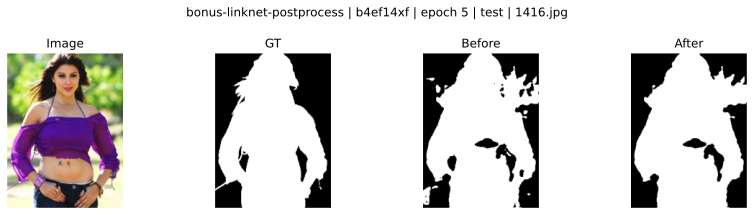

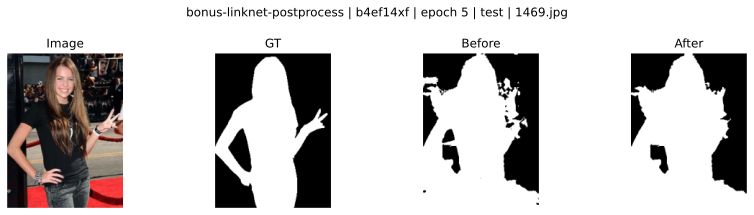

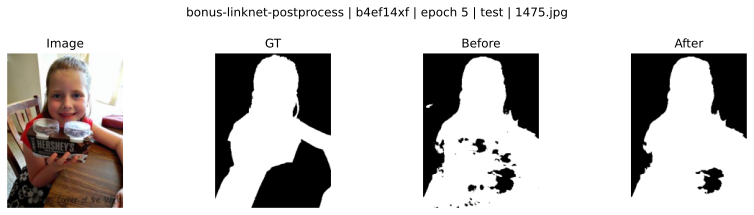

global_step,▁
postprocess/gain,▁
postprocess/iou_after,▁
postprocess/iou_before,▁
global_step,1
postprocess/area_threshold,500
postprocess/epoch,5
postprocess/gain,0.00418
postprocess/iou_after,0.86993
postprocess/iou_before,0.86574
postprocess/min_size,500


In [39]:
from glob import glob

path = max(
    glob(f"{"/content/drive/MyDrive/dl2-hw-3"}/linknet-bce_dice_1_0.5/wandb/run-*/files/best.pt"),
    key=os.path.getmtime
)
checkpoint = torch.load(path, map_location="cpu", weights_only=False)

model = LinkNet().to("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(checkpoint["model"])

folder = f"{LOG_ROOT}/bonus-linknet-postprocess"
os.makedirs(folder, exist_ok=True)

with wandb.init(
    project="dl2-segmentation",
    name="bonus-linknet-postprocess",
    dir=folder,
    config={"checkpoint": path}
) as run:
    bonus_results["LinkNet + BCE + 0.5 Dice"] = evaluate_postprocessing(
        model, test_data_loader, run, 1, checkpoint["epoch"]
    )

не смотря на то что сам прирос небольшой, видно, что качество сегментации на картинках стало прям лучше и стабильнее.

## `Бонус: существенное улучшение качества (2 балла)`

Придумайте какой-нибудь трюк, который существенно (с учётом бонусного пункта 1) повысит качество (которое должно быть и так достаточно высоко). Не разрешается использовать дополнительные данные или другие предобученные кодировщики кроме VGG13.

Если вы что-то попробовали, но качество не повысилось, всё равно оформите этот пункт, даже за неудачные попытки могут быть начислены баллы.

In [29]:
class LinkNetDecoderBlockRefined(LinkNetDecoderBlock):
    def __init__(self, out_channels):
        super().__init__(out_channels)
        self.bn1 = torch.nn.BatchNorm2d(out_channels)
        self.bn2 = torch.nn.BatchNorm2d(out_channels)

    def forward(self, down, left):
        x = self.upconv(torch.nn.functional.interpolate(down, scale_factor=2, mode="nearest")) + left
        out = self.relu(self.bn1(self.conv1(x)))
        return self.relu(self.bn2(self.conv2(out)) + x)


class LinkNetDecoderRefined(Decoder):
    def __init__(self, num_filters, num_blocks):
        torch.nn.Module.__init__(self)
        self.blocks = torch.nn.ModuleList(
            LinkNetDecoderBlockRefined(num_filters * 2 ** idx) for idx in reversed(range(num_blocks))
        )


class LinkNetRefined(LinkNet):
    def __init__(self, num_classes=1, num_blocks=4):
        super().__init__(num_classes, num_blocks)
        self.decoder = LinkNetDecoderRefined(64, num_blocks - 1)


In [30]:
class LinkNetSupervision(LinkNetRefined):
    def __init__(self):
        super().__init__()
        self.aux_heads = torch.nn.ModuleList([
            torch.nn.Conv2d(256, 1, 1), torch.nn.Conv2d(128, 1, 1)
        ])

    def forward(self, images, return_aux=False):
        acts = self.encoder(images)
        x, features = acts[-1], []
        for block, left in zip(self.decoder.blocks, acts[-2::-1]):
            x = block(x, left)
            features.append(x)
        logits = self.final(x)
        if self.training or return_aux:
            aux = [torch.nn.functional.interpolate(head(feature), size=logits.shape[-2:],
                                                    mode="bilinear", align_corners=False)
                   for head, feature in zip(self.aux_heads, features)]
            return logits, aux
        return logits


In [31]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
config = {"lr": 1e-3, "epochs": 12, "num_blocks": 4, "seed": 42,
          "finetune_epoch": 10, "finetune_lr": 1e-4, "restore_best": True, "postprocess": True, "loss_name": "bce_dice_1_0.5",
          "aux_weights": [0.5, 0.25]}
model = train_experiment(
    LinkNetSupervision(), train_data_loader, test_data_loader,
    loss_configs["bce_dice_1_0.5"], config, "bonus-refined-supervision-bce-dice-1-0.5"
)
bonus_results["Refined + Deep supervision"] = model.bonus_scores
del model
torch.cuda.empty_cache()


wandb: WARNING When using several event log directories, please call `wandb.tensorboard.patch(root_logdir="...")` before `wandb.init`


bonus-refined-supervision-bce-dice-1-0.5 | iwljdmw7 | Files: /content/drive/MyDrive/dl2-hw-3-submit/bonus-refined-supervision-bce-dice-1-0.5/wandb/run-20261102_100121-iwljdmw7/files


Epoch 1/12 | train:   0%|          | 0/169 [00:00<?, ?it/s]

Epoch 1/12 | test:   0%|          | 0/18 [00:00<?, ?it/s]

bonus-refined-supervision-bce-dice-1-0.5 | Epoch 1: train loss=0.7472, test loss=0.3737, test IoU=0.8194


Epoch 2/12 | train:   0%|          | 0/169 [00:00<?, ?it/s]

... (31 outputs left out)

bonus-refined-supervision-bce-dice-1-0.5 | Epoch 12: train loss=0.1617, test loss=0.1777, test IoU=0.9124


Traceback (most recent call last):
  File "/tmp/ipykernel_750/2171209266.py", line 79, in train_experiment
    checkpoint = torch.load(os.path.join(run.dir, "best.pt"), map_location=device)
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 1578, in load
    raise pickle.UnpicklingError(_get_wo_message(str(e))) from None
_pickle.UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL

batch/dice,▁▆▄▆▆▅▇▆▆▆▅▇█▄▇▇▆▆▆▅▄▆▇▆▇▆█▇▇▇▆▇▆█▆█████
batch/iou,▁▅▆▅▇▆▆▇▅▇▅▅▆▅▄▇▇▇▆▆▆▇▆▆▇▇▇▆█▇▇▇█▇█▇▇███
batch/loss,█▆▅▄▅▄▄▃▃▃▄▃▄▃▄▂▃▂▂▁▂▄▂▂▂▄▃▃▃▂▂▄▂▂▁▂▁▁▁▂
epoch,▁▂▂▃▄▄▅▅▆▇▇█
global_step,▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▇████
lr,██████████▁▁
norm/gradients,▃█▂▃▄▆▂▄▂▂▃▂▂▂▂▂▂▃▂▂▃▂▁▂▂▂▂▂▂▂▃▂▂▁▂▁▂▂▁▂
norm/weights,▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▆▆▆▆▆▆▇▇▇███████
test/dice,▁▃▄▅▅▆▆▆▅▇██
test/iou,▁▃▄▅▅▆▆▆▅▇██
+4,...


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [32]:
from pathlib import Path

folder = Path(LOG_ROOT) / "bonus-refined-supervision-bce-dice-1-0.5"
path = folder / "wandb/run-20261102_100121-iwljdmw7/files/best.pt"

checkpoint = torch.load(path, map_location="cpu", weights_only=False)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LinkNetSupervision().to(device)
model.load_state_dict(checkpoint["model"])

<All keys matched successfully>

Test IoU: 0.9124 → 0.9155; прирост: +0.0030


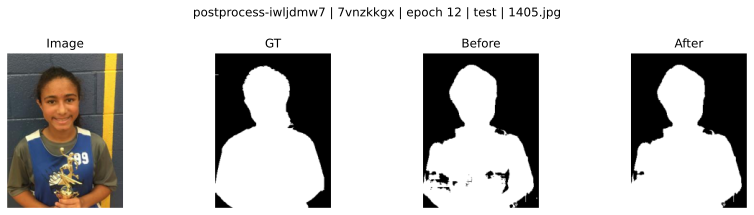

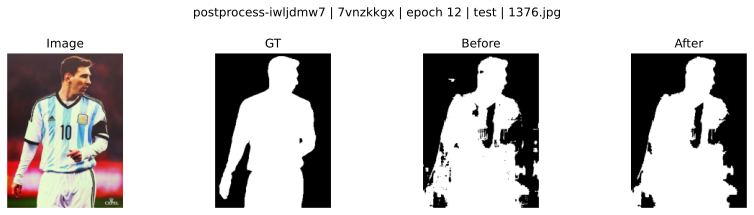

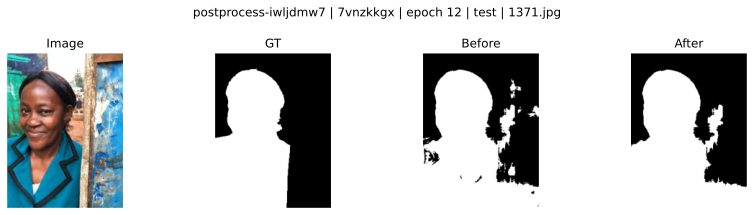

global_step,▁
postprocess/gain,▁
postprocess/iou_after,▁
postprocess/iou_before,▁
global_step,1
postprocess/area_threshold,500
postprocess/epoch,12
postprocess/gain,0.00304
postprocess/iou_after,0.91546
postprocess/iou_before,0.91242
postprocess/min_size,500


NameError: name 'bonus_results' is not defined

In [33]:
output_dir = folder / "postprocess-iwljdmw7"
output_dir.mkdir(exist_ok=True)

with wandb.init(
    project="dl2-segmentation",
    name="postprocess-iwljdmw7",
    dir=str(output_dir),
    config={"source_run": "iwljdmw7", "checkpoint": str(path)}
) as run:
    scores = evaluate_postprocessing(
        model, test_data_loader, run, 1, checkpoint["epoch"]
    )

bonus_results["Refined + Deep supervision"] = scores

In [35]:
bonus_results = {"Refined + Deep supervision": scores}

## `Бонус: обучение с использованием сторонних фреймворков (1 балл)`

Попробуйте обучить свою модель с использованием одного из следующих фреймворков: [catalyst](https://github.com/catalyst-team/catalyst), [pytorch-lightning](https://www.pytorchlightning.ai/), [ignite](https://github.com/pytorch/ignite).

## `Бонус: аугментации (0.5 балла)`

Воспользуйтесь сторонними библиотеками для аугментаций, например, [deepaugment](https://github.com/barisozmen/deepaugment) и [albumentations](https://albumentations.ai/) для улучшения качества модели.

## `Бонус: torch.compile (0.25 балла)`

Попробуйте установить [Pytorch 2.0](https://pytorch.org/get-started/pytorch-2.0/) и запустите обучение с использованием `torch.compile`. Тщательно сравните время с и без использованием компиляции.

*Замечание:* обязательно укажите конфигурацию системы (версия OS, модель CPU/GPU, объём RAM), на которой производилось обучение. В частности, приложите вывод команд:
```bash
! nvcc --version
! nvidia-smi
```